**Simulação Computacional - Projecto Mecânico - Aula Prática 7**

<br>

# Outras formas de obter as equações do Elemento de Barra (*Truss*)

<br>

Agora que já temos uma visão mais consolidade dos princípios gerais do método de elementos finitos para a solução de problemas estruturais, vamos ainda dentro do exemplo do elemento barra discutir formais mais gerais de chegar às equações do elemento que terão aplicação em elementos mais complexos e de físicas não estruturais, ou onde conceitos físicos de energia potencial não têm lugar.

<br>

Esta aula segue um livro diferente, aqui a referência usada foi o *Hutton: Fundamentals of Finite Element Analysis*, no seu capítulo 5 *Method of Weighted
Residuals*.





---

## Abordagem do Método de Resíduos Ponderados de Galerkin

O Método de Galerkin é uma das abordagens mais comuns para derivar as equações do Método dos Elementos Finitos (MEF), especialmente quando o princípio da energia potencial mínima não é facilmente aplicável (e.g., problemas de transporte de calor, fluxo de fluidos). Ele é baseado no método dos resíduos ponderados, onde a equação diferencial governante é satisfeita de forma aproximada. Em termos gerais procura-se uma função de teste que aproxime a variável independente que queremos encontrar, como o deslocamento ou a temperatura, num problema definido por uma equação diferencial.

<br>

No entanto esta função de teste não vai conseguir satizfazer a totalidade da equação diferencial no seu domínio, substituindo o desconhecido pela função de teste na equação diferencial governante nasce o seu resíduo que é minimizado nesse volume para se encontrar a solução.

<br>

### 1. Equação Diferencial Governante

Para um elemento de barra axialmente carregado, a equação diferencial de equilíbrio em termos de deslocamento $u(x)$ é:

$$ \frac{d}{dx} \left( EA \frac{du}{dx} \right) + b = 0 $$

Onde:
*   $E$ é o módulo de elasticidade do material.
*   $A$ é a área da seção transversal.
*   $u(x)$ é o deslocamento axial.
*   $b$ é a força de corpo por unidade de comprimento.

Esta equação governante do nosso problema regra geral é contínua no espaço, pelo que é conhecida como forma forte do problema.

<br>

### 2. Forma Fraca (Weighted Residual Form)

No Método de Galerkin, procuramos uma solução aproximada para $u(x)$, denotada por $\hat{u}(x)$, que satisfaça a equação governante. A substituição de $\hat{u}(x)$ na equação geralmente resultará em um resíduo $R$ (erro).

$$ R = \frac{d}{dx} \left( EA \frac{d\hat{u}}{dx} \right) + b \ne 0 $$

<br>

O Método de Galerkin em particular exige que o resíduo seja ortogonal a um conjunto de funções de ponderação (ou teste) $W_i(x)$. No Galerkin, as funções de ponderação são as mesmas funções de forma usadas para aproximar o deslocamento.

Integrando o resíduo ponderado sobre o domínio do elemento (comprimento $L$) e igualando a zero:

$$ \int_0^L W_i \left( \frac{d}{dx} \left( EA \frac{d\hat{u}}{dx} \right) + b \right) dx = 0 \quad \text{para } i = 1, 2, \dots, n $$

Onde $n$ é o número de graus de liberdade do elemento.

<br>

Para alcançar um formulação fraca do problema, uma formulação computável, aplicamos a integração por partes ao primeiro termo para reduzir a ordem da derivada e transferir a diferenciação para a função de ponderação (isso também permite a inclusão natural das condições de fronteira):

$$ \int_0^L W_i \frac{d}{dx} \left( EA \frac{d\hat{u}}{dx} \right) dx = \left[ W_i EA \frac{d\hat{u}}{dx} \right]_0^L - \int_0^L EA \frac{d\hat{u}}{dx} \frac{dW_i}{dx} dx $$

<br>

Substituindo de volta na equação do resíduo ponderado:

$$ - \int_0^L EA \frac{d\hat{u}}{dx} \frac{dW_i}{dx} dx + \left[ W_i EA \frac{d\hat{u}}{dx} \right]_0^L + \int_0^L W_i b dx = 0 $$

<br>

As condições de contorno no termo $\left[ W_i EA \frac{d\hat{u}}{dx} \right]_0^L$ representam as forças nodais ($F_x$ em $x=L$ e $-F_x$ em $x=0$, onde $F_x = EA \frac{d\hat{u}}{dx}$):

$$ \left[ W_i F_x \right]_0^L = W_i(L) F_x(L) - W_i(0) F_x(0) $$

<br>

### 3. Discretização e Funções de Forma

Para um elemento de barra com dois nós, o deslocamento $\hat{u}(x)$ é aproximado usando funções de forma $N_j(x)$ e deslocamentos nodais $d_j$:

$$ \hat{u}(x) = N_1(x) d_1 + N_2(x) d_2 = \mathbf{N} \mathbf{d}^e $$

No método de Galerkin, uma das suas características é que as suas funções de ponderação $W_i(x)$ são as mesmas funções de forma $N_i(x)$.

Assim, temos:

$$ \frac{d\hat{u}}{dx} = \frac{dN_1}{dx} d_1 + \frac{dN_2}{dx} d_2 = \mathbf{B} \mathbf{d}^e $$

onde $W_i = N_i$.

<br>

### 4. Derivação da Matriz de Rigidez

Substituindo as aproximações e as funções de ponderação na forma fraca:

$$ \sum_{j=1}^2 \left( \int_0^L EA \frac{dN_i}{dx} \frac{dN_j}{dx} dx \right) d_j = \left[ N_i F_x \right]_0^L + \int_0^L N_i b dx $$

Este conjunto de equações pode ser escrito na forma matricial como:

$$ \mathbf{K}^e \mathbf{d}^e = \mathbf{F}^e $$

Onde a matriz de rigidez do elemento $\mathbf{K}^e$ é definida por seus componentes:

$$ K_{ij}^e = \int_0^L EA \frac{dN_i}{dx} \frac{dN_j}{dx} dx $$

E o vetor de forças nodais equivalentes $\mathbf{F}^e$ é composto pelas forças de contorno e pelas forças de corpo:

$$ F_i^e = \left[ N_i F_x \right]_0^L + \int_0^L N_i b dx $$

Para as funções de forma lineares de um elemento de barra ($N_1 = 1 - \frac{x}{L}$, $N_2 = \frac{x}{L}$):

$$ \frac{dN_1}{dx} = -\frac{1}{L} \quad \text{e} \quad \frac{dN_2}{dx} = \frac{1}{L} $$

Calculando os termos da matriz de rigidez:

$k_{11}^e = \int_0^L EA \left( -\frac{1}{L} \right) \left( -\frac{1}{L} \right) dx = \int_0^L \frac{EA}{L^2} dx = \frac{EA}{L^2} [x]_0^L = \frac{EA}{L^2} L = \frac{EA}{L}$

$k_{12}^e = \int_0^L EA \left( -\frac{1}{L} \right) \left( \frac{1}{L} \right) dx = \int_0^L -\frac{EA}{L^2} dx = -\frac{EA}{L}$

$k_{21}^e = \int_0^L EA \left( \frac{1}{L} \right) \left( -\frac{1}{L} \right) dx = \int_0^L -\frac{EA}{L^2} dx = -\frac{EA}{L}$

$k_{22}^e = \int_0^L EA \left( \frac{1}{L} \right) \left( \frac{1}{L} \right) dx = \int_0^L \frac{EA}{L^2} dx = \frac{EA}{L}$

Assim, a matriz de rigidez do elemento de barra é:

$$ \mathbf{k}^e = \frac{EA}{L} \begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix} $$

Esta é a mesma matriz de rigidez obtida pelo princípio da energia potencial mínima e pelo método directo, demonstrando a consistência entre os métodos.

---

### Passo-a-Passo do Método de Galerkin para um problema 1D

Nosso objetivo é resolver a equação diferencial:
$$ \frac{d^2u}{dx^2} + u + x = 0 \quad \text{com } u(0)=0, u(1)=0 $$

<br>

**Passo 1: Escolher uma Solução de Teste**

Precisamos de uma função de teste $\hat{u}(x)$ que satisfaça as condições de fronteira. Para $u(0)=0$ e $u(1)=0$, uma escolha simples é:

$$ \hat{u}(x) = c_1 x (1-x) $$

<br>

**Passo 2: Calcular o Resíduo**

O resíduo $R(x; c_1)$ é obtido substituindo $\hat{u}(x)$ na equação diferencial (EDO):
$$ R(x; c_1) = \frac{d^2\hat{u}}{dx^2} + \hat{u} + x $$

<br>

**Passo 3: Aplicar a Ortogonalidade de Galerkin**

O método de Galerkin exige que o resíduo seja ortogonal à função de ponderação (que é a base da função de teste $\phi_1 = x(1-x)$):
$$ \int_0^1 R(x; c_1) \cdot \phi_1(x) \, dx = 0 $$

<br>

**Passo 4: Resolver para os Coeficientes**

Avalie a integral para encontrar o valor de $c_1$.

<br>

**Passo 5: Solução Final**

Substitua $c_1$ de volta em $\hat{u}(x)$.

In [ ]:
import sympy as sp

# Definir símbolos
x = sp.Symbol('x')
c1 = sp.Symbol('c1')

# Passo 1: Solução de teste u_hat = c1 * phi1
phi1 = x * (1 - x)
u_hat = c1 * phi1

# Passo 2: Calcular o Resíduo R
# EDO: u'' + u + x = 0
residual = sp.diff(u_hat, x, 2) + u_hat + x
print(f"Resíduo R(x): {residual}")

# Passo 3 & 4: Condição de Ortogonalidade de Galerkin (Integrar R * phi1 = 0)
weighted_residual = residual * phi1
integral_result = sp.integrate(weighted_residual, (x, 0, 1))
equation = sp.Eq(integral_result, 0)

# Resolver para c1
sol = sp.solve(equation, c1)
c1_val = sol[0]
print(f"Coeficiente resolvido c1: {c1_val}")

# Passo 5: Solução Aproximada Final
final_u = u_hat.subs(c1, c1_val)
print(f"\nSolução Aproximada Final u(x) ≈ {final_u}")

# Comparar com a solução exata no ponto médio x=0.5
exact_sol = sp.sin(x)/sp.sin(1) - x
print(f"\nAproximação em x=0.5: {final_u.subs(x, 0.5).evalf():.5f}")
print(f"Exata em x=0.5:       {exact_sol.subs(x, 0.5).evalf():.5f}")

Resíduo R(x): c1*x*(1 - x) - 2*c1 + x
Coeficiente resolvido c1: 5/18

Solução Aproximada Final u(x) ≈ 5*x*(1 - x)/18

Aproximação em x=0.5: 0.06944
Exata em x=0.5:       0.06975


---

### Melhorando a Aproximação com Duas Funções de Teste ($n=2$)

Para aumentar a precisão, adicionamos um segundo termo que também cumpre as condições fronteiras $x=0$ e $x=1$:

$$ \hat{u}(x) = c_1 \phi_1(x) + c_2 \phi_2(x) = c_1 x(1-x) + c_2 x^2(1-x) $$

<br>

Neste caso temos agora duas equações de ortogonalidade de Galerkin para determinar as constantes $c_1$ e $c_2$:
$$ \int_0^1 R(x; c_1, c_2) \cdot \phi_1(x) \, dx = 0 $$
$$ \int_0^1 R(x; c_1, c_2) \cdot \phi_2(x) \, dx = 0 $$

In [ ]:
import sympy as sp

# Definir símbolos
x = sp.Symbol('x')
c1, c2 = sp.symbols('c1 c2')

# Passo 1: Nova solução de teste com duas funções de base
phi1 = x * (1 - x)
phi2 = x**2 * (1 - x)
u_hat_2 = c1 * phi1 + c2 * phi2

# Passo 2: Calcular o novo Resíduo R
# EDO: u'' + u + x = 0
residual_2 = sp.diff(u_hat_2, x, 2) + u_hat_2 + x
print(f"Novo Resíduo R(x): {sp.simplify(residual_2)}")

# Passo 3: Aplicar as duas condições de ortogonalidade de Galerkin
eq1 = sp.integrate(residual_2 * phi1, (x, 0, 1))
eq2 = sp.integrate(residual_2 * phi2, (x, 0, 1))

# Passo 4: Resolver o sistema linear para c1 e c2
sol_2 = sp.solve([sp.Eq(eq1, 0), sp.Eq(eq2, 0)], (c1, c2))
print(f"Coeficientes resolvidos: c1 = {sol_2[c1]}, c2 = {sol_2[c2]}")

# Passo 5: Solução Aproximada Final com n=2
final_u_2 = u_hat_2.subs(sol_2)
print(f"\nSolução Aproximada u(x) com n=2: {sp.simplify(final_u_2)}")

# Comparação com a solução exata no ponto médio
exact_sol = sp.sin(x)/sp.sin(1) - x
print(f"\nAproximação (n=1) em x=0.5: 0.06944")
print(f"Aproximação (n=2) em x=0.5: {final_u_2.subs(x, 0.5).evalf():.5f}")
print(f"Solução Exata em x=0.5:     {exact_sol.subs(x, 0.5).evalf():.5f}")

Novo Resíduo R(x): -c1*x*(x - 1) - 2*c1 - c2*x**2*(x - 1) - 4*c2*x - 2*c2*(x - 1) + x
Coeficientes resolvidos: c1 = 71/369, c2 = 7/41

Solução Aproximada u(x) com n=2: x*(-63*x**2 - 8*x + 71)/369

Aproximação (n=1) em x=0.5: 0.06944
Aproximação (n=2) em x=0.5: 0.06944
Solução Exata em x=0.5:     0.06975


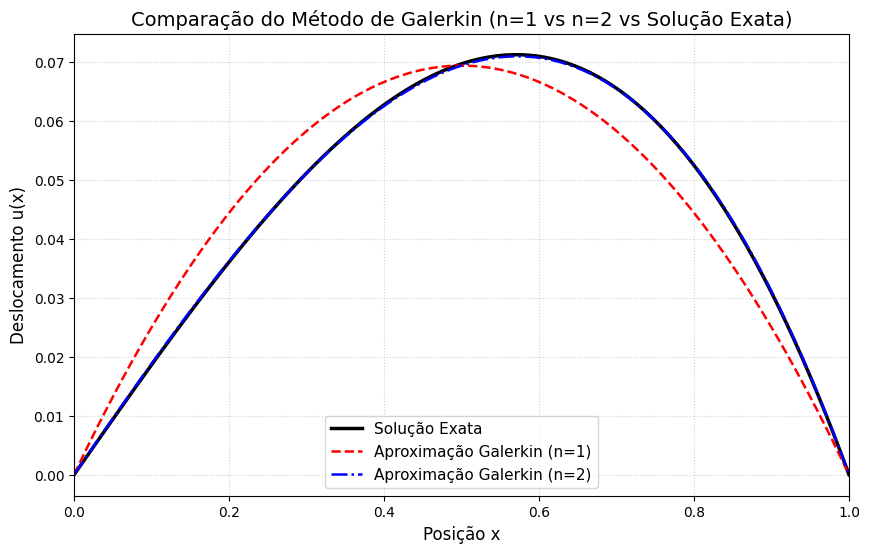

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Gerar pontos no domínio [0, 1]
x_vals = np.linspace(0, 1, 100)

# 1. Solução Exata: u(x) = sin(x)/sin(1) - x
u_exata = np.sin(x_vals) / np.sin(1) - x_vals

# 2. Aproximação n=1: u(x) = 5 * x * (1 - x) / 18
u_approx_1 = 5 * x_vals * (1 - x_vals) / 18

# 3. Aproximação n=2: u(x) = x * (-63*x**2 - 8*x + 71) / 369
u_approx_2 = x_vals * (-63 * x_vals**2 - 8 * x_vals + 71) / 369

# Criar a figura para comparação gráfica
plt.figure(figsize=(10, 6))
plt.plot(x_vals, u_exata, 'k-', linewidth=2.5, label='Solução Exata')
plt.plot(x_vals, u_approx_1, 'r--', linewidth=1.8, label='Aproximação Galerkin (n=1)')
plt.plot(x_vals, u_approx_2, 'b-.', linewidth=1.8, label='Aproximação Galerkin (n=2)')

# Configurações estéticas do gráfico
plt.title('Comparação do Método de Galerkin (n=1 vs n=2 vs Solução Exata)', fontsize=14)
plt.xlabel('Posição x', fontsize=12)
plt.ylabel('Deslocamento u(x)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.xlim(0, 1)
plt.show()

---

# Exercício de Consolidação (5.1)

Usando o método de Galerkin dos resíduos ponderados obtém uma solução aproximada da equação diferencial:

$$
\frac{d^2y}{dx^2} - 10x² = 5
$$

onde $0 \leq x \leq 1$ e as condições de fronteira são $y(0)=y(1)=0$

Tem em consideração que uma regra geral para uma função de teste que cumpra condições de fronteira homogéneas pode ser dada por:

$$
N(x) = (x-x_a)^p (x-x_b)^q
$$

<br>

onde as condições de fronteira se aplicam em $x=a$ e em $x=b$ e onde $p$ e $q$ são inteiros positivos maiores que zero.

---

## Exemplo

Vamos resolver o exercício 3.59 da página 148 do *FEM First Course - Logan 5th Edition*.

(3.59) Para o problema de barras da figura abaixo é aplicada uma tensão no topo com 34 N/m, usa o método de Galerkin com uma função de teste polinomial quadrática $u(x)=c_1x+c_2x²$. $A$ é igual a 0,0012 $m²$ e $E$ tem o valor de 206 GPa.


```text
[Fixo sem rotação]
     (0)                  (0.76m)                (1,52m)                
    Nó 1 ----------------- Nó 2------------------ Nó 3
      |                      |                      |       
   f1x,d1x                f2x,d2x                f3x, dx3         
```

<br>










In [ ]:
import sympy as sp

# Define símbolos para as variáveis e constantes
x = sp.Symbol('x')
c2 = sp.Symbol('c2') # Usaremos apenas c2 após aplicar as C.C.
E, A, L = sp.symbols('E A L') # Módulo de Elasticidade, Área da seção, Comprimento
b = sp.Symbol('b') # Carga distribuída

# Parâmetros do problema
L_val = 1.52 # metros
b_val = 34 # N/m
A_val = 0.0012 # m^2
E_val = 206 * (10**9) # Pa (206 GPa = 206 * 10^9 Pa)

print("### Solução do Problema 3.59 (Método de Galerkin)\n")

# 1. Definição da Função de Teste Aproximada (Trial Solution)
print("# 1. Definição da Função de Teste Aproximada (Trial Solution)\n")
print(f"   A função de teste polinomial quadrática sugerida é u(x) = c1*x + c2*x**2.")
print(f"   As condições de contorno são u(0)=0 e u(L)=0 (onde L={L_val} m).")
print(f"   Aplicando u(0)=0: c1*(0) + c2*(0)**2 = 0, o que é sempre satisfeito.")
print(f"   Aplicando u(L)=0: c1*L + c2*L**2 = 0 => c1 = -c2*L.")
print(f"   Substituindo c1 de volta na função de teste, obtemos uma função com um único parâmetro c2:")

# u_hat(x) = c2*(x**2 - L*x) = c2*x*(x-L)
phi1 = x * (x - L)
u_hat = c2 * phi1

print(f"   u_hat(x) = {sp.simplify(u_hat.subs(L, L_val))}\n")

# 2. Cálculo do Resíduo (Residual)
print("# 2. Cálculo do Resíduo (Residual)\n")
print(f"   A equação diferencial governante para uma barra axial com carga distribuída (b) é:")
print(f"   d/dx(EA du/dx) + b = 0")
print(f"   Assumindo EA constante, a equação simplifica para: EA * d²u/dx² + b = 0\n")

d_u_hat_dx = sp.diff(u_hat, x)
d2_u_hat_dx2 = sp.diff(d_u_hat_dx, x)

residual = E * A * d2_u_hat_dx2 + b

print(f"   Calculamos a segunda derivada de u_hat(x): d²u_hat/dx² = {d2_u_hat_dx2}\n")
print(f"   Substituindo na ODE, o resíduo R(x) é:")
print(f"   R(x) = {residual.subs(b, b_val)}\n")

# 3. Aplicação da Condição de Ortogonalidade de Galerkin
print("# 3. Aplicação da Condição de Ortogonalidade de Galerkin\n")
print(f"   No Método de Galerkin, a função de ponderação (W) é a mesma base da função de teste (phi1).")
print(f"   A condição de ortogonalidade requer que a integral do resíduo ponderado seja zero:")
print(f"   Integral[ R(x) * phi1(x) dx ] de 0 a L = 0\n")

weighted_residual = residual * phi1
integral_expr = sp.integrate(weighted_residual, (x, 0, L))

print(f"   O integrando é: ({residual.subs(b, b_val)}) * ({phi1.subs(L, L_val)})")

# 4. Resolução para os Coeficientes
print("# 4. Resolução para os Coeficientes\n")
# Substitui o valor numérico de L na expressão integral antes de resolver
integral_result_subs_L = integral_expr.subs(L, L_val)
equation = sp.Eq(integral_result_subs_L, 0)

print(f"   Após a integração, a equação para c2 é: {equation}\n")
sol = sp.solve(equation, c2)
c2_val_symbolic = sol[0]

print(f"   Resolvendo para c2 (forma simbólica), obtemos: c2 = {c2_val_symbolic}\n")

# Agora, substituímos os valores numéricos de b, A e E
c2_val_numeric = c2_val_symbolic.subs({b: b_val, A: A_val, E: E_val})
print(f"   Substituindo os valores numéricos (b={b_val}, A={A_val}, E={E_val/1e9} GPa), c2 = {c2_val_numeric.evalf()}\n")

# 5. Solução Aproximada Final
print("# 5. Solução Aproximada Final\n")
final_u_symbolic = u_hat.subs(c2, c2_val_symbolic).subs(L, L_val)

print(f"   Substituindo o valor de c2 (simbólico) de volta na função de teste u_hat(x):")
print(f"   u(x) \u2248 {final_u_symbolic}\n")
print(f"   Esta é a solução aproximada para o deslocamento u(x) em função de E e A.\n")

# Solução final com valores numéricos
final_u_numeric = final_u_symbolic.subs({b: b_val, A: A_val, E: E_val})
print(f"   Solução aproximada com todos os valores numéricos:")
print(f"   u(x) \u2248 {final_u_numeric.evalf()}\n")


### Solução do Problema 3.59 (Método de Galerkin)

# 1. Definição da Função de Teste Aproximada (Trial Solution)

   A função de teste polinomial quadrática sugerida é u(x) = c1*x + c2*x**2.
   As condições de contorno são u(0)=0 e u(L)=0 (onde L=1.52 m).
   Aplicando u(0)=0: c1*(0) + c2*(0)**2 = 0, o que é sempre satisfeito.
   Aplicando u(L)=0: c1*L + c2*L**2 = 0 => c1 = -c2*L.
   Substituindo c1 de volta na função de teste, obtemos uma função com um único parâmetro c2:
   u_hat(x) = c2*x*(x - 1.52)

# 2. Cálculo do Resíduo (Residual)

   A equação diferencial governante para uma barra axial com carga distribuída (b) é:
   d/dx(EA du/dx) + b = 0
   Assumindo EA constante, a equação simplifica para: EA * d²u/dx² + b = 0

   Calculamos a segunda derivada de u_hat(x): d²u_hat/dx² = 2*c2

   Substituindo na ODE, o resíduo R(x) é:
   R(x) = 2*A*E*c2 + 34

# 3. Aplicação da Condição de Ortogonalidade de Galerkin

   No Método de Galerkin, a função de ponderação (W) é a mesma base da função